<a href="https://colab.research.google.com/github/naylaviona/Studi-Kasus-Informatics-Practitioner-Lecture-Series/blob/main/StudiKasus6(BART_SLACHTER).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STUDI KASUS 6: ATTRIBUTING DIRECT DRIVERS TO DEFORESTATION ALERTS WITH SATELLITE IMAGERY AND AI

# PEMATERI: BART SLACHTER

## Judul Studi Kasus: Klasifikasi Penyebab Deforestasi Menggunakan Algoritma Random Forest Berdasarkan Ekstraksi Fitur Spasial

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# 1. GENERATE DATASET SIMULASI (Mengadopsi fitur yang disebut Dr. Bart)
# Fitur: Luas Area (Hektar), Titik Api (1=Ya, 0=Tidak), Jarak ke Sungai (km), Jarak ke Jalan (km)
np.random.seed(42)
n_samples = 1000

data = {
    'luas_area_ha': np.random.uniform(0.5, 100, n_samples),
    'titik_api_terdeteksi': np.random.choice([0, 1], n_samples, p=[0.7, 0.3]),
    'jarak_ke_sungai_km': np.random.uniform(0.1, 20, n_samples),
    'jarak_ke_jalan_km': np.random.uniform(0.1, 50, n_samples),
}
df = pd.DataFrame(data)

In [3]:
# Logika Pelabelan Sintetis (Sesuai paparan materi co-occurrence & pattern)
def tentukan_driver(row):
    # Jika luas sangat besar dan ada jalan dekat -> Pertanian Skala Besar
    if row['luas_area_ha'] > 50 and row['jarak_ke_jalan_km'] < 10:
        return 'Pertanian Besar'
    # Jika ada titik api dan sangat dekat sungai -> Kebakaran (Confusion dengan banjir di materi)
    elif row['titik_api_terdeteksi'] == 1 and row['jarak_ke_sungai_km'] < 2:
        return 'Kebakaran Liar'
    # Jika area kecil tapi banyak jalan -> Penebangan (Selective Logging)
    elif row['luas_area_ha'] < 10 and row['jarak_ke_jalan_km'] < 5:
        return 'Penebangan'
    # Sisanya diklasifikasi sebagai Pertambangan atau Pertanian Kecil
    else:
        return np.random.choice(['Pertambangan', 'Pertanian Kecil'])

df['driver_deforestasi'] = df.apply(tentukan_driver, axis=1)

In [4]:
# 2. SPLIT DATA (Training & Testing)
X = df[['luas_area_ha', 'titik_api_terdeteksi', 'jarak_ke_sungai_km', 'jarak_ke_jalan_km']]
y = df['driver_deforestasi']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [6]:
# 3. TRAINING MODEL (Menggunakan Random Forest Classifier)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [7]:
# 4. EVALUASI MODEL
y_pred = model.predict(X_test)
print("=== HASIL EVALUASI MODEL MACHINE LEARNING ===\n")
print(f"Akurasi Total: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred))

=== HASIL EVALUASI MODEL MACHINE LEARNING ===

Akurasi Total: 55.60%

Laporan Klasifikasi:
                 precision    recall  f1-score   support

 Kebakaran Liar       1.00      0.93      0.97        15
     Penebangan       0.50      1.00      0.67         1
   Pertambangan       0.46      0.52      0.49       102
Pertanian Besar       1.00      1.00      1.00        21
Pertanian Kecil       0.51      0.45      0.48       111

       accuracy                           0.56       250
      macro avg       0.69      0.78      0.72       250
   weighted avg       0.56      0.56      0.56       250



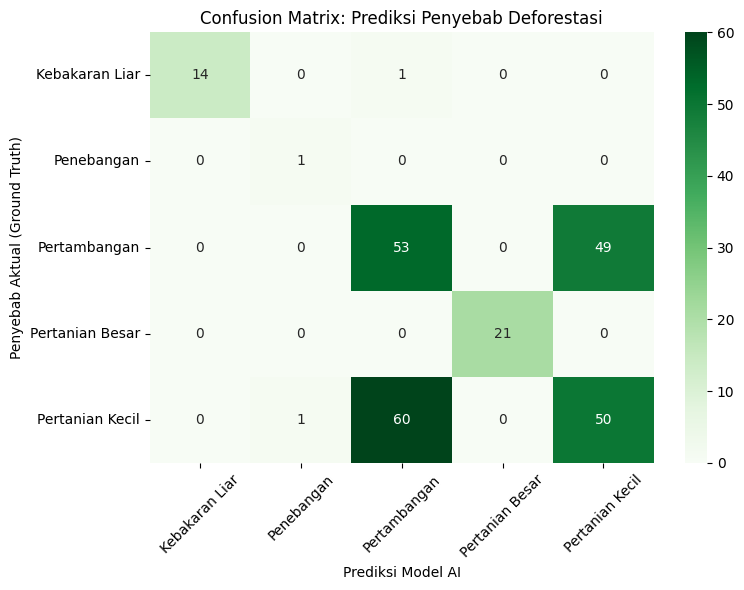

In [8]:
# 5. VISUALISASI CONFUSION MATRIX
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix: Prediksi Penyebab Deforestasi')
plt.ylabel('Penyebab Aktual (Ground Truth)')
plt.xlabel('Prediksi Model AI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# 6. FEATURE IMPORTANCE (Melihat fitur apa yang paling berpengaruh)
importances = model.feature_importances_
for fitur, imp in zip(X.columns, importances):
    print(f"Kepentingan Fitur '{fitur}': {imp*100:.2f}%")

Kepentingan Fitur 'luas_area_ha': 31.92%
Kepentingan Fitur 'titik_api_terdeteksi': 4.60%
Kepentingan Fitur 'jarak_ke_sungai_km': 25.83%
Kepentingan Fitur 'jarak_ke_jalan_km': 37.65%
